# Tugas 1 - Data Preprocessing (Penambangan Data)

## 1. Pendahuluan

**Nama** : Marry Desy Chatrin Ora (NIM 3022410031)
**Partner** : Abdul Azis (NIM 3022410703)
**Kasus** : Analisis Data Kunjungan Pasien dan Pelayanan Rumah Sakit (data sintetis)

Notebook ini memuat seluruh tahapan preprocessing pada dataset yang diterima dari partner. Setiap bagian ditulis dengan pola **Input - Proses - Output**.

Penomoran bagian mengikuti laporan PDF. Urutan pengerjaan:
- Bagian 2 : Pemuatan dan eksplorasi awal data
- Bagian 3 : Data Cleansing (redundant whitespace, mistake during data entry, impossible value, missing value, outlier)
- Bagian 4 : Data Transformation (normalization, discretization, measurement, aggregation)
- Bagian 5 : Data Integration (joining table dan appending table dengan pd.concat)
- Bagian 6 : Ringkasan hasil

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
os.makedirs('figs', exist_ok=True)
os.makedirs('hasil', exist_ok=True)

R = {}   # ringkasan angka penting, dipakai untuk menyusun laporan

## 2. Eksplorasi Awal Data

**Input** : 9 file CSV dari partner (dataset utama, dua tabel untuk join, dua tabel kunjungan bulanan, dua tabel pelayanan beda satuan, dua tabel agregasi harian dan mingguan).
**Proses** : membaca data dengan `pd.read_csv`, lalu memeriksa ukuran, tipe data, missing value, dan statistik ringkas.
**Output** : gambaran awal kualitas data pada `dataset_awal.csv`.

In [2]:
df_awal   = pd.read_csv('dataset_awal.csv')
pasien    = pd.read_csv('data_pasien.csv')
kunjungan = pd.read_csv('data_kunjungan.csv')
k_jan     = pd.read_csv('kunjungan_januari.csv')
k_feb     = pd.read_csv('kunjungan_februari.csv')
pel_menit = pd.read_csv('pelayanan_menit.csv')
pel_detik = pd.read_csv('pelayanan_detik.csv')
harian    = pd.read_csv('kunjungan_harian.csv')
mingguan  = pd.read_csv('kunjungan_mingguan.csv')

ukuran = {
    'dataset_awal': df_awal.shape, 'data_pasien': pasien.shape, 'data_kunjungan': kunjungan.shape,
    'kunjungan_januari': k_jan.shape, 'kunjungan_februari': k_feb.shape,
    'pelayanan_menit': pel_menit.shape, 'pelayanan_detik': pel_detik.shape,
    'kunjungan_harian': harian.shape, 'kunjungan_mingguan': mingguan.shape}
R['ukuran'] = {k: list(v) for k, v in ukuran.items()}
pd.DataFrame(ukuran, index=['baris', 'kolom']).T

,baris,kolom
dataset_awal,300,18
data_pasien,280,6
data_kunjungan,320,8
kunjungan_januari,70,8
kunjungan_februari,62,8
pelayanan_menit,190,9
pelayanan_detik,190,9
kunjungan_harian,472,5
kunjungan_mingguan,96,6


In [3]:
df_awal.head(10)

,Visit_ID,Patient_ID,Patient_Name,Gender,Age,Blood_Type,Department,Diagnosis_Category,Visit_Type,Visit_Date,Blood_Pressure,Body_Temperature,Weight,Height,Waiting_Time,Consultation_Duration,Treatment_Cost,Satisfaction_Score
0,V0001,P0006,Mega Julianto,Female,51.0,b,-,Musculoskeletal,Rawat Jalan,2026-01-01,131/85,36.2,67.4,154.0,15.0,15.0,25.0,5.0
1,V0002,P0066,Indah Sulistyo,Perempuan,31.0,O,INTERNAL MEDICINE,Gastrointestinal,Rawat Jln,2026-01-01,119/74,NaN,69.6,155.7,46.0,NaN,417000.0,2.0
2,V0003,P0140,Mega Yulianto,-,32.0,A,-,cardiovascular,Rawat Jalan,2026-01-01,145/93,35.5,71.1,-150.0,8.0,16.0,7500.0,NaN
3,V0004,P0190,Fajar Purnomo,M,31.0,B,dermatology,Skin Disorder,Rawat Jalan,2026-01-01,106/71,36.6,64.5,166.8,10.0,5.0,421000.0,4.0
4,V0005,P0246,Imam Firmansyah,Male,71.0,A,Internal Medicine,Cardiovascular,Rawat-Jalan,2026-01-01,126/69,36.6,NaN,158.1,43.0,23.0,383000.0,3.0
5,V0006,P0007,Retno Prasetyo,FEMALE,13.0,A,Pediatrics,Infectious Disease,Rawat Jalan,2026-01-02,126/74,38.0,43.0,144.1,33.0,11.0,297000.0,3.0
6,V0007,P0069,Dedi Mahendra,male,30.0,B,Internal Medicine,Infectious Diseas,Rawat Jalan,2026-01-02,129/79,38.3,76.8,169.3,72.0,19.0,412000.0,2.0
7,V0008,P0087,Dedi Wijaya,M,31.0,a,Neurology,Neurological,Rawat jalan,2026-01-02,116/77,36.8,51.0,NaN,17.0,21.0,476000.0,4.0
8,V0009,P0096,Novi Basuki,Female,52.0,B,Dermatology,Skin Disorders,Rawat Inap,2026-01-02,116/78,36.6,NaN,161.5,13.0,47.0,8956000.0,4.0
9,V0010,P0256,Reza Sulistyo,Male,NaN,a,Internal Med,Gastrointestinal,Rawat Jalan,2026-01-03,113/84,36.8,84.5,174.5,9.0,27.0,500000.0,5.0


In [4]:
df_awal.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Visit_ID               300 non-null    str    
 1   Patient_ID             300 non-null    str    
 2   Patient_Name           300 non-null    str    
 3   Gender                 295 non-null    str    
 4   Age                    288 non-null    float64
 5   Blood_Type             289 non-null    str    
 6   Department             296 non-null    str    
 7   Diagnosis_Category     294 non-null    str    
 8   Visit_Type             300 non-null    str    
 9   Visit_Date             300 non-null    str    
 10  Blood_Pressure         296 non-null    str    
 11  Body_Temperature       286 non-null    float64
 12  Weight                 287 non-null    float64
 13  Height                 292 non-null    float64
 14  Waiting_Time           288 non-null    float64
 15  Consultation_Dura

In [5]:
kolom_num = ['Age', 'Body_Temperature', 'Weight', 'Height', 'Waiting_Time',
             'Consultation_Duration', 'Treatment_Cost', 'Satisfaction_Score']
kolom_kat = ['Gender', 'Blood_Type', 'Department', 'Diagnosis_Category', 'Visit_Type', 'Blood_Pressure']

mv_awal = df_awal.isna().sum()
R['missing_awal'] = {k: int(v) for k, v in mv_awal.items() if v > 0}
R['duplikat_awal'] = int(df_awal.duplicated().sum())
R['duplikat_visit_id'] = int(df_awal['Visit_ID'].duplicated().sum())
print('Baris duplikat penuh       :', R['duplikat_awal'])
print('Visit_ID duplikat          :', R['duplikat_visit_id'])
print('Jumlah missing value total :', int(mv_awal.sum()))
mv_awal[mv_awal > 0]

Baris duplikat penuh       : 0
Visit_ID duplikat          : 0
Jumlah missing value total : 127


Gender                    5
Age                      12
Blood_Type               11
Department                4
Diagnosis_Category        6
Blood_Pressure            4
Body_Temperature         14
Weight                   13
Height                    8
Waiting_Time             12
Consultation_Duration     9
Treatment_Cost           11
Satisfaction_Score       18
dtype: int64

In [6]:
df_awal[kolom_num].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,288.0,4.197569e+01,6.262517e+01,-10.0,18.000,35.00,59.00,999.0
Body_Temperature,286.0,3.883357e+01,2.165995e+01,-5.0,36.600,36.80,37.10,370.0
Weight,287.0,5.079627e+02,5.420625e+03,-20.0,47.300,57.50,65.95,71500.0
Height,292.0,1.503680e+02,4.030402e+01,-150.0,149.275,158.35,164.50,500.0
Waiting_Time,288.0,3.415972e+01,8.793517e+01,-60.0,15.000,24.00,37.00,1440.0
Consultation_Duration,291.0,2.698969e+01,6.402933e+01,-25.0,13.000,18.00,24.00,900.0
Treatment_Cost,289.0,5.691798e+06,5.606622e+07,-450000.0,373000.000,451000.00,573000.00,950000000.0
Satisfaction_Score,282.0,4.432624e+00,5.727259e+00,-1.0,4.000,4.00,5.00,99.0


In [7]:
# jumlah nilai unik per kolom kategorik sebelum dibersihkan
R['unik_sebelum'] = {c: int(df_awal[c].nunique()) for c in kolom_kat}
pd.Series(R['unik_sebelum'], name='nilai_unik_awal')

Gender                 27
Blood_Type             20
Department             69
Diagnosis_Category     69
Visit_Type             37
Blood_Pressure        274
Name: nilai_unik_awal, dtype: int64

Hasil eksplorasi menunjukkan kolom kategorik memiliki terlalu banyak nilai unik (misalnya `Gender` yang seharusnya hanya 2 nilai), nilai numerik yang tidak masuk akal (usia 999, suhu 370, biaya negatif), dan missing value pada kolom kategorik maupun numerik. Semua masalah tersebut ditangani pada bagian berikut.

## 3. Data Cleansing

Pengerjaan dilakukan pada salinan data (`df`) agar `df_awal` tetap utuh sebagai pembanding.

### 3.1 Redundant Whitespace

**Input** : seluruh kolom bertipe teks pada `df_awal`.
**Proses** : menghapus spasi di awal dan akhir (`str.strip`), lalu mengganti spasi ganda di tengah teks dengan satu spasi (`str.replace`). Jumlah sel yang berubah dihitung sebagai bukti.
**Output** : kolom teks tanpa spasi berlebih.

In [8]:
df = df_awal.copy()
kolom_teks = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]

jumlah_spasi = {}
for c in kolom_teks:
    asli = df[c]
    bersih = asli.str.strip().str.replace(r'\s+', ' ', regex=True)
    jumlah_spasi[c] = int(((asli != bersih) & asli.notna()).sum())
    df[c] = bersih

R['spasi'] = jumlah_spasi
R['spasi_total'] = int(sum(jumlah_spasi.values()))
print('Total sel dengan spasi berlebih:', R['spasi_total'])
pd.Series(jumlah_spasi, name='sel_diperbaiki')[lambda s: s > 0]

Total sel dengan spasi berlebih: 160


Patient_Name          24
Gender                15
Blood_Type            13
Department            35
Diagnosis_Category    23
Visit_Type            36
Blood_Pressure        14
Name: sel_diperbaiki, dtype: int64

### 3.2 Mistake during Data Entry

**Input** : kolom `Patient_Name`, `Gender`, `Blood_Type`, `Department`, `Diagnosis_Category`, `Visit_Type`, dan `Blood_Pressure`.
**Proses** :
- Nama pasien diseragamkan menjadi format judul (huruf awal kapital).
- Kategori yang ditulis dengan huruf besar/kecil berbeda, singkatan, bahasa berbeda, atau salah ketik dipetakan ke satu label baku memakai kamus pemetaan.
- Tanda `-` dan `Unknown` dianggap penanda data kosong dan diubah menjadi `NaN`.
- Tekanan darah yang formatnya beragam (`112 / 73`, `133/77 mmHg`, `117-82`) diseragamkan menjadi `sistolik/diastolik`, lalu dipisah menjadi dua kolom numerik.

**Output** : kolom kategorik dengan label baku dan dua kolom tekanan darah numerik.

In [9]:
PETA = {
 'Gender': {'female': 'Female', 'f': 'Female', 'perempuan': 'Female',
            'male': 'Male', 'm': 'Male', 'laki laki': 'Male'},
 'Blood_Type': {'a': 'A', 'b': 'B', 'ab': 'AB', 'o': 'O', '0': 'O'},
 'Department': {
    'internal medicine': 'Internal Medicine', 'penyakit dalam': 'Internal Medicine', 'internal med': 'Internal Medicine',
    'cardiology': 'Cardiology', 'cardiologi': 'Cardiology', 'cardilogy': 'Cardiology',
    'neurology': 'Neurology', 'nerology': 'Neurology', 'neurologi': 'Neurology',
    'orthopedics': 'Orthopedics', 'orthopaedics': 'Orthopedics', 'ortopedi': 'Orthopedics',
    'pediatrics': 'Pediatrics', 'paediatrics': 'Pediatrics', 'pediatri': 'Pediatrics',
    'ent': 'ENT', 'e.n.t': 'ENT', 'tht': 'ENT',
    'dermatology': 'Dermatology', 'dermatologi': 'Dermatology', 'dermatolgy': 'Dermatology',
    'obstetrics': 'Obstetrics', 'obstetrik': 'Obstetrics', 'obstetri': 'Obstetrics'},
 'Diagnosis_Category': {
    'musculoskeletal': 'Musculoskeletal', 'musculoskeletel': 'Musculoskeletal',
    'cardiovascular': 'Cardiovascular', 'cardiovasculer': 'Cardiovascular',
    'skin disorder': 'Skin Disorder', 'skin disorders': 'Skin Disorder',
    'respiratory': 'Respiratory', 'respiratori': 'Respiratory',
    'gastrointestinal': 'Gastrointestinal', 'gastro intestinal': 'Gastrointestinal',
    'infectious disease': 'Infectious Disease', 'infectious diseas': 'Infectious Disease',
    'neurological': 'Neurological', 'neurologic': 'Neurological',
    'metabolic/endocrine': 'Metabolic/Endocrine', 'metabolic': 'Metabolic/Endocrine',
    'ent disorder': 'ENT Disorder', 'maternal health': 'Maternal Health',
    'injury/trauma': 'Injury/Trauma', 'injury': 'Injury/Trauma',
    'mental health': 'Mental Health', 'allergy': 'Allergy', 'alergy': 'Allergy',
    'gynecological': 'Gynecological'},
 'Visit_Type': {'rawat jalan': 'Rawat Jalan', 'rawat jln': 'Rawat Jalan',
                'rawat inap': 'Rawat Inap', 'rawat inp': 'Rawat Inap'},
}

def standarkan(seri, peta, tampil=True):
    kunci = (seri.str.lower().str.replace('-', ' ', regex=False)
                 .str.replace(r'\s+', ' ', regex=True).str.strip())
    kunci = kunci.replace({'': np.nan, 'unknown': np.nan})
    hasil = kunci.map(peta)
    tak_terpetakan = kunci[kunci.notna() & hasil.isna()].unique()
    if tampil and len(tak_terpetakan):
        print('Nilai belum terpetakan:', tak_terpetakan)
    return hasil

df['Patient_Name'] = df['Patient_Name'].str.title()
for c in ['Gender', 'Blood_Type', 'Department', 'Diagnosis_Category', 'Visit_Type']:
    df[c] = standarkan(df[c], PETA[c])

R['unik_sesudah'] = {c: int(df[c].nunique()) for c in ['Gender', 'Blood_Type', 'Department', 'Diagnosis_Category', 'Visit_Type']}
tabel_unik = pd.DataFrame({'sebelum': pd.Series(R['unik_sebelum']), 'sesudah': pd.Series(R['unik_sesudah'])}).dropna()
tabel_unik

,sebelum,sesudah
Blood_Type,20,4.0
Department,69,8.0
Diagnosis_Category,69,14.0
Gender,27,2.0
Visit_Type,37,2.0


In [10]:
# placeholder '-' / 'Unknown' yang dikonversi menjadi NaN akan dihitung bersama missing value di tahap 3.4
for c in ['Gender', 'Blood_Type', 'Department', 'Diagnosis_Category', 'Visit_Type']:
    print(c, '->', sorted(df[c].dropna().unique()))

Gender -> ['Female', 'Male']
Blood_Type -> ['A', 'AB', 'B', 'O']
Department -> ['Cardiology', 'Dermatology', 'ENT', 'Internal Medicine', 'Neurology', 'Obstetrics', 'Orthopedics', 'Pediatrics']
Diagnosis_Category -> ['Allergy', 'Cardiovascular', 'ENT Disorder', 'Gastrointestinal', 'Gynecological', 'Infectious Disease', 'Injury/Trauma', 'Maternal Health', 'Mental Health', 'Metabolic/Endocrine', 'Musculoskeletal', 'Neurological', 'Respiratory', 'Skin Disorder']
Visit_Type -> ['Rawat Inap', 'Rawat Jalan']


In [11]:
# Tekanan darah: seragamkan format lalu pisahkan menjadi Systolic dan Diastolic
bp_asli = df['Blood_Pressure']
format_baku = bp_asli.str.match(r'^\d{2,3}/\d{2,3}$')
bp_salah_format = int((bp_asli.notna() & ~format_baku & (bp_asli != '-')).sum())
R['bp_salah_format'] = bp_salah_format

bp = (bp_asli.str.lower().str.replace('mmhg', '', regex=False)
             .str.replace(' ', '', regex=False).str.replace('-', '/', regex=False))
pecah = bp.str.extract(r'^(\d{2,3})/(\d{2,3})$').astype(float)
df['Systolic'], df['Diastolic'] = pecah[0], pecah[1]
print('Tekanan darah dengan format tidak baku (spasi/mmHg/tanda minus):', bp_salah_format)
df[['Blood_Pressure', 'Systolic', 'Diastolic']].loc[bp_asli.notna() & ~format_baku].head(10)

Tekanan darah dengan format tidak baku (spasi/mmHg/tanda minus): 10


,Blood_Pressure,Systolic,Diastolic
35,112 / 73,112.0,73.0
42,133/77 mmHg,133.0,77.0
55,0/0,NaN,NaN
62,-,NaN,NaN
70,-,NaN,NaN
126,117-82,117.0,82.0
144,128/72 mmHg,128.0,72.0
157,-,NaN,NaN
223,-,NaN,NaN
256,125/90 mmHg,125.0,90.0


### 3.3 Impossible Value

**Input** : kolom numerik yang sudah dirapikan.
**Proses** : setiap kolom diperiksa dengan batas wajar secara medis. Nilai yang jelas merupakan kesalahan satuan diperbaiki dengan konversi, sedangkan nilai yang tidak dapat dipulihkan diganti `NaN` agar ditangani pada tahap missing value.

| Kolom | Batas wajar | Perbaikan satuan |
|---|---|---|
| Age | 0 - 110 tahun | tidak ada |
| Body_Temperature | 34 - 42 derajat C | 90-110 dianggap Fahrenheit dan dikonversi; 300-450 dianggap salah titik desimal dan dibagi 10 |
| Weight | 2 - 250 kg | nilai 1000 ke atas dianggap gram dan dibagi 1000 |
| Height | 40 - 230 cm | nilai 1 - 2,5 dianggap meter dan dikali 100 |
| Waiting_Time | 0 - 480 menit | tidak ada |
| Consultation_Duration | 1 - 240 menit | tidak ada |
| Treatment_Cost | Rp10.000 - Rp100.000.000 | tidak ada |
| Satisfaction_Score | 1 - 5 | tidak ada |
| Systolic / Diastolic | 70-250 / 40-150 dan sistolik lebih besar dari diastolik | tidak ada |

**Output** : kolom numerik tanpa nilai mustahil, beserta jumlah nilai yang diperbaiki dan yang dikosongkan.

In [12]:
log_imp = []   # (kolom, aturan, jumlah)

def catat(kolom, aturan, n):
    log_imp.append({'Kolom': kolom, 'Tindakan': aturan, 'Jumlah': int(n)})

# --- Suhu tubuh
t = df['Body_Temperature']
m_f = t.between(90, 110)
m_d = t.between(300, 450)
t = t.where(~m_f, ((t - 32) * 5 / 9).round(1))
t = t.where(~m_d, (t / 10).round(1))
catat('Body_Temperature', 'Fahrenheit dikonversi ke Celsius', m_f.sum())
catat('Body_Temperature', 'Salah titik desimal (dibagi 10)', m_d.sum())
m_x = t.notna() & ~t.between(34, 42)
catat('Body_Temperature', 'Di luar 34-42 menjadi NaN', m_x.sum())
df['Body_Temperature'] = t.where(~m_x)

# --- Berat badan
w = df['Weight']
m_g = w >= 1000
w = w.where(~m_g, w / 1000)
catat('Weight', 'Gram dikonversi ke kg', m_g.sum())
m_x = w.notna() & ~w.between(2, 250)
catat('Weight', 'Di luar 2-250 menjadi NaN', m_x.sum())
df['Weight'] = w.where(~m_x)

# --- Tinggi badan
h = df['Height']
m_m = h.between(1.0, 2.5)
h = h.where(~m_m, h * 100)
catat('Height', 'Meter dikonversi ke cm', m_m.sum())
m_x = h.notna() & ~h.between(40, 230)
catat('Height', 'Di luar 40-230 menjadi NaN', m_x.sum())
df['Height'] = h.where(~m_x)

# --- Batas sederhana untuk kolom lain
batas = {'Age': (0, 110), 'Waiting_Time': (0, 480), 'Consultation_Duration': (1, 240),
         'Treatment_Cost': (10_000, 100_000_000), 'Satisfaction_Score': (1, 5),
         'Systolic': (70, 250), 'Diastolic': (40, 150)}
for c, (lo, hi) in batas.items():
    m_x = df[c].notna() & ~df[c].between(lo, hi)
    catat(c, f'Di luar {lo:,}-{hi:,} menjadi NaN'.replace(',', '.'), m_x.sum())
    df[c] = df[c].where(~m_x)

# sistolik harus lebih besar dari diastolik
m_bp = df['Systolic'].notna() & df['Diastolic'].notna() & (df['Systolic'] <= df['Diastolic'])
catat('Systolic/Diastolic', 'Sistolik <= diastolik menjadi NaN', m_bp.sum())
df.loc[m_bp, ['Systolic', 'Diastolic']] = np.nan

# --- Tanggal kunjungan
df['Visit_Date'] = pd.to_datetime(df['Visit_Date'], format='%Y-%m-%d', errors='coerce')
m_tgl = df['Visit_Date'].isna() | ~df['Visit_Date'].between('2026-01-01', '2026-05-31')
catat('Visit_Date', 'Tanggal tidak valid / di luar periode', m_tgl.sum())

tabel_imp = pd.DataFrame(log_imp)
R['impossible'] = log_imp
R['impossible_total'] = int(tabel_imp['Jumlah'].sum())
tabel_imp[tabel_imp['Jumlah'] > 0]

,Kolom,Tindakan,Jumlah
0,Body_Temperature,Fahrenheit dikonversi ke Celsius,5
1,Body_Temperature,Salah titik desimal (dibagi 10),1
2,Body_Temperature,Di luar 34-42 menjadi NaN,3
3,Weight,Gram dikonversi ke kg,2
4,Weight,Di luar 2-250 menjadi NaN,4
5,Height,Meter dikonversi ke cm,4
6,Height,Di luar 40-230 menjadi NaN,4
7,Age,Di luar 0-110 menjadi NaN,5
8,Waiting_Time,Di luar 0-480 menjadi NaN,4
9,Consultation_Duration,Di luar 1-240 menjadi NaN,4


In [13]:
# Pemeriksaan konsistensi logis antarvariabel (hanya dilaporkan, tidak diubah)
obst_pria = int(((df['Department'] == 'Obstetrics') & (df['Gender'] == 'Male')).sum())
pedi_dewasa = int(((df['Department'] == 'Pediatrics') & (df['Age'] >= 18)).sum())
R['logis'] = {'obstetrics_pria': obst_pria, 'pediatrics_dewasa': pedi_dewasa}
print('Kunjungan Obstetrics dengan pasien laki-laki :', obst_pria)
print('Kunjungan Pediatrics dengan pasien >= 18 th  :', pedi_dewasa)

Kunjungan Obstetrics dengan pasien laki-laki : 0
Kunjungan Pediatrics dengan pasien >= 18 th  : 0


### 3.4 Missing Value

**Input** : data setelah tahap impossible value. Nilai yang dikosongkan pada tahap sebelumnya ikut dihitung sebagai missing.
**Proses** :
1. Menghitung jumlah dan persentase missing per kolom.
2. Menghitung statistik deskriptif (mean, median, standar deviasi, skewness) untuk kolom numerik dan modus untuk kolom kategorik.
3. Memilih nilai pengisi berdasarkan statistik tersebut:
   - Kolom numerik yang miring (|skewness| > 0,5) diisi **median**, sedangkan yang simetris diisi **mean**.
   - `Waiting_Time`, `Consultation_Duration`, `Treatment_Cost` diisi **median per jenis kunjungan** karena rawat inap dan rawat jalan berbeda jauh.
   - `Weight` dan `Height` diisi **median per kelompok usia** karena anak dan dewasa berbeda jauh.
   - `Age` diisi median per poliklinik.
   - `Satisfaction_Score` (skala ordinal) diisi **modus**.
   - `Gender` dan `Blood_Type` diisi **modus**; `Department` dan `Diagnosis_Category` diisi **modus berdasarkan pasangannya** (poliklinik menentukan diagnosis dan sebaliknya).

**Output** : dataset tanpa missing value dan tabel ringkasan nilai pengisi.

In [14]:
kolom_num2 = ['Age', 'Body_Temperature', 'Weight', 'Height', 'Waiting_Time', 'Consultation_Duration',
              'Treatment_Cost', 'Satisfaction_Score', 'Systolic', 'Diastolic']
kolom_kat2 = ['Gender', 'Blood_Type', 'Department', 'Diagnosis_Category']

mv = df[kolom_kat2 + kolom_num2].isna().sum()
tabel_mv = pd.DataFrame({'Missing': mv, 'Persen': (mv / len(df) * 100).round(2)})
R['missing_sebelum_impute'] = {k: int(v) for k, v in mv.items()}
R['missing_total_sebelum'] = int(mv.sum())
print('Total missing value sebelum imputasi:', int(mv.sum()))
tabel_mv

Total missing value sebelum imputasi: 206


,Missing,Persen
Gender,12,4.00
Blood_Type,15,5.00
Department,10,3.33
Diagnosis_Category,14,4.67
Age,17,5.67
Body_Temperature,17,5.67
Weight,17,5.67
Height,12,4.00
Waiting_Time,16,5.33
Consultation_Duration,13,4.33


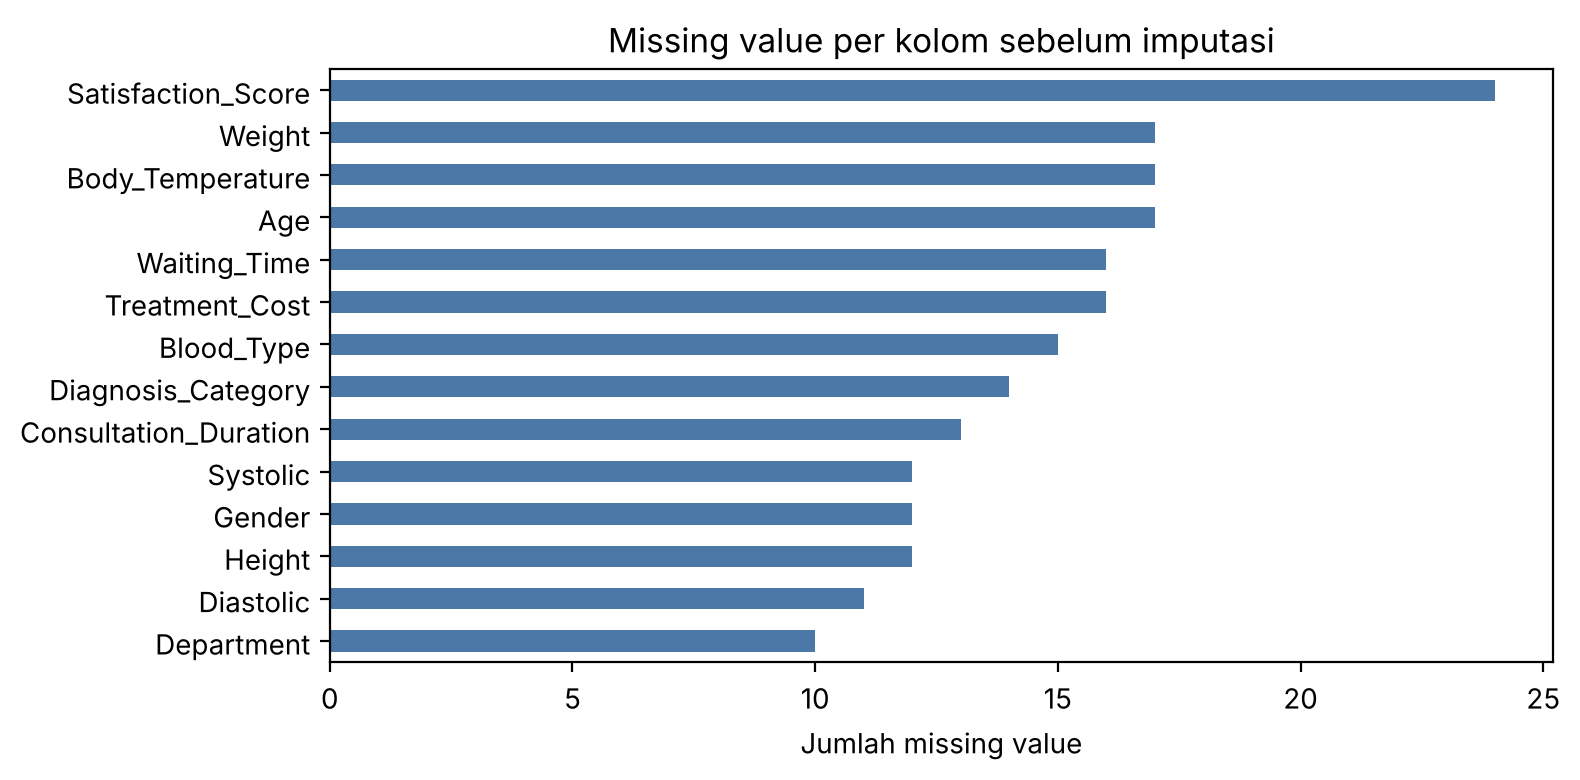

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
tabel_mv['Missing'].sort_values().plot.barh(ax=ax, color='#4C78A8')
ax.set_xlabel('Jumlah missing value'); ax.set_title('Missing value per kolom sebelum imputasi')
plt.tight_layout(); plt.savefig('figs/missing_sebelum.png', dpi=150); plt.show()

In [16]:
# Statistik deskriptif kolom numerik (dasar pemilihan nilai pengisi)
stat = df[kolom_num2].agg(['count', 'mean', 'median', 'std', 'min', 'max', 'skew']).T.round(2)
R['stat_sebelum'] = stat.reset_index().rename(columns={'index': 'Kolom'}).to_dict('records')
stat

,count,mean,median,std,min,max,skew
Age,283.0,37.73,35.0,22.19,0.0,101.0,0.37
Body_Temperature,283.0,36.93,36.8,0.64,35.5,39.0,1.36
Weight,283.0,55.79,58.0,18.39,4.3,147.4,-0.07
Height,288.0,153.44,158.7,20.94,53.8,179.4,-2.38
Waiting_Time,284.0,29.90,24.0,28.08,3.0,240.0,4.22
Consultation_Duration,287.0,22.26,18.0,17.54,5.0,140.0,3.13
Treatment_Cost,284.0,2448845.07,453500.0,6080911.88,213000.0,58000000.0,5.42
Satisfaction_Score,276.0,4.09,4.0,0.75,2.0,5.0,-0.63
Systolic,288.0,120.47,120.0,15.61,83.0,163.0,0.22
Diastolic,289.0,76.88,77.0,11.15,50.0,150.0,0.87


In [17]:
# Modus kolom kategorik
modus = {c: df[c].mode()[0] for c in kolom_kat2}
R['modus'] = modus
pd.Series(modus, name='modus')

Gender                           Female
Blood_Type                            B
Department            Internal Medicine
Diagnosis_Category       Cardiovascular
Name: modus, dtype: str

In [18]:
def kelompok_usia(a):
    return pd.cut(a, bins=[-1, 12, 17, 59, 200], labels=['Anak', 'Remaja', 'Dewasa', 'Lansia'])

ringkas = []   # catatan nilai pengisi
def catat_imp(kolom, n, metode, contoh):
    ringkas.append({'Kolom': kolom, 'Missing': int(n), 'Metode': metode, 'Nilai pengisi': contoh})

# ---- Kategorik
peta_dept = df.dropna(subset=['Department', 'Diagnosis_Category']).groupby('Diagnosis_Category')['Department'].agg(lambda s: s.mode()[0])
peta_diag = df.dropna(subset=['Department', 'Diagnosis_Category']).groupby('Department')['Diagnosis_Category'].agg(lambda s: s.mode()[0])

dept_asli, diag_asli = df['Department'].copy(), df['Diagnosis_Category'].copy()
n_dept, n_diag = dept_asli.isna().sum(), diag_asli.isna().sum()

df['Department'] = dept_asli.fillna(diag_asli.map(peta_dept)).fillna(modus['Department'])
df['Diagnosis_Category'] = diag_asli.fillna(dept_asli.map(peta_diag))
df['Diagnosis_Category'] = df['Diagnosis_Category'].fillna(df['Department'].map(peta_diag))

catat_imp('Department', n_dept, 'Modus berdasarkan diagnosis', 'bervariasi')
catat_imp('Diagnosis_Category', n_diag, 'Modus berdasarkan poliklinik', 'bervariasi')
for c in ['Gender', 'Blood_Type']:
    n = df[c].isna().sum()
    df[c] = df[c].fillna(modus[c])
    catat_imp(c, n, 'Modus', modus[c])

# ---- Numerik
n = df['Age'].isna().sum()
df['Age'] = df['Age'].fillna(df.groupby('Department')['Age'].transform('median')).fillna(df['Age'].median()).round()
catat_imp('Age', n, 'Median per poliklinik', 'bervariasi')

df['Kelompok_Usia_Tmp'] = kelompok_usia(df['Age'])
for c in ['Weight', 'Height']:
    n = df[c].isna().sum()
    df[c] = df[c].fillna(df.groupby('Kelompok_Usia_Tmp', observed=True)[c].transform('median')).round(1)
    catat_imp(c, n, 'Median per kelompok usia', 'bervariasi')
df = df.drop(columns='Kelompok_Usia_Tmp')

for c in ['Waiting_Time', 'Consultation_Duration', 'Treatment_Cost']:
    n = df[c].isna().sum()
    med = df.groupby('Visit_Type')[c].transform('median')
    df[c] = df[c].fillna(med).fillna(df[c].median())
    catat_imp(c, n, 'Median per jenis kunjungan', 'bervariasi')

n = df['Satisfaction_Score'].isna().sum()
mod_sat = df['Satisfaction_Score'].mode()[0]
df['Satisfaction_Score'] = df['Satisfaction_Score'].fillna(mod_sat)
catat_imp('Satisfaction_Score', n, 'Modus', int(mod_sat))

for c in ['Body_Temperature', 'Systolic', 'Diastolic']:
    n = df[c].isna().sum()
    sk = df[c].skew()
    if abs(sk) > 0.5:
        isi_val, met = df[c].median(), f'Median (skewness {sk:.2f})'
    else:
        isi_val, met = df[c].mean(), f'Mean (skewness {sk:.2f})'
    df[c] = df[c].fillna(isi_val).round(1)
    catat_imp(c, n, met, round(float(isi_val), 2))

tabel_ringkas = pd.DataFrame(ringkas)
R['imputasi'] = ringkas
R['missing_total_sesudah'] = int(df.drop(columns=['Blood_Pressure']).isna().sum().sum())
print('Missing value setelah imputasi:', R['missing_total_sesudah'])
tabel_ringkas

Missing value setelah imputasi: 0


,Kolom,Missing,Metode,Nilai pengisi
0,Department,10,Modus berdasarkan diagnosis,bervariasi
1,Diagnosis_Category,14,Modus berdasarkan poliklinik,bervariasi
2,Gender,12,Modus,Female
3,Blood_Type,15,Modus,B
4,Age,17,Median per poliklinik,bervariasi
5,Weight,17,Median per kelompok usia,bervariasi
6,Height,12,Median per kelompok usia,bervariasi
7,Waiting_Time,16,Median per jenis kunjungan,bervariasi
8,Consultation_Duration,13,Median per jenis kunjungan,bervariasi
9,Treatment_Cost,16,Median per jenis kunjungan,bervariasi


In [19]:
# Tekanan darah teks dibangun ulang dari nilai numerik yang sudah lengkap
df['Blood_Pressure'] = df['Systolic'].astype(int).astype(str) + '/' + df['Diastolic'].astype(int).astype(str)
df['Age'] = df['Age'].astype(int)
df['Satisfaction_Score'] = df['Satisfaction_Score'].astype(int)
df.isna().sum().sum()

np.int64(0)

### 3.5 Outlier

**Input** : dataset tanpa missing value.
**Proses** : outlier dideteksi dengan metode **IQR** (nilai di bawah Q1 - 1,5 x IQR atau di atas Q3 + 1,5 x IQR). Untuk `Waiting_Time`, `Consultation_Duration`, dan `Treatment_Cost`, batas dihitung **per jenis kunjungan** karena biaya rawat inap memang berbeda skala dengan rawat jalan. Nilai outlier ditangani dengan **winsorizing** (dipotong ke batas atas atau bawah), sehingga jumlah baris tidak berkurang.
Kolom `Age`, `Weight`, `Height`, dan `Body_Temperature` hanya dihitung, tidak diubah, karena sebarannya yang lebar memang wajar (campuran anak dan dewasa, serta demam).
**Output** : jumlah outlier per kolom dan kolom yang sudah di-winsorize.

In [20]:
def batas_iqr(s):
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

# Hitung outlier semua kolom numerik (global)
hitung = {}
for c in ['Age', 'Body_Temperature', 'Weight', 'Height', 'Systolic', 'Diastolic', 'Satisfaction_Score']:
    lo, hi = batas_iqr(df[c])
    hitung[c] = int(((df[c] < lo) | (df[c] > hi)).sum())

cost_sebelum = df['Treatment_Cost'].copy()
wait_sebelum = df['Waiting_Time'].copy()
tangani = ['Waiting_Time', 'Consultation_Duration', 'Treatment_Cost']
detail = []
for c in tangani:
    n_out = 0
    for jenis, idx in df.groupby('Visit_Type').groups.items():
        lo, hi = batas_iqr(df.loc[idx, c])
        m = (df.loc[idx, c] < lo) | (df.loc[idx, c] > hi)
        n_out += int(m.sum())
        df.loc[idx, c] = df.loc[idx, c].clip(lower=max(lo, 0), upper=hi)
        detail.append({'Kolom': c, 'Jenis kunjungan': jenis, 'Batas bawah': round(lo, 1), 'Batas atas': round(hi, 1), 'Outlier': int(m.sum())})
    hitung[c] = n_out

R['outlier'] = hitung
R['outlier_detail'] = detail
R['outlier_ditangani'] = int(sum(hitung[c] for c in tangani))
pd.DataFrame(detail)

,Kolom,Jenis kunjungan,Batas bawah,Batas atas,Outlier
0,Waiting_Time,Rawat Inap,-5.9,39.1,3
1,Waiting_Time,Rawat Jalan,-14.5,69.5,11
2,Consultation_Duration,Rawat Inap,4.5,82.5,4
3,Consultation_Duration,Rawat Jalan,1.5,29.5,5
4,Treatment_Cost,Rawat Inap,-4207125.0,22229875.0,4
5,Treatment_Cost,Rawat Jalan,195500.0,649500.0,4


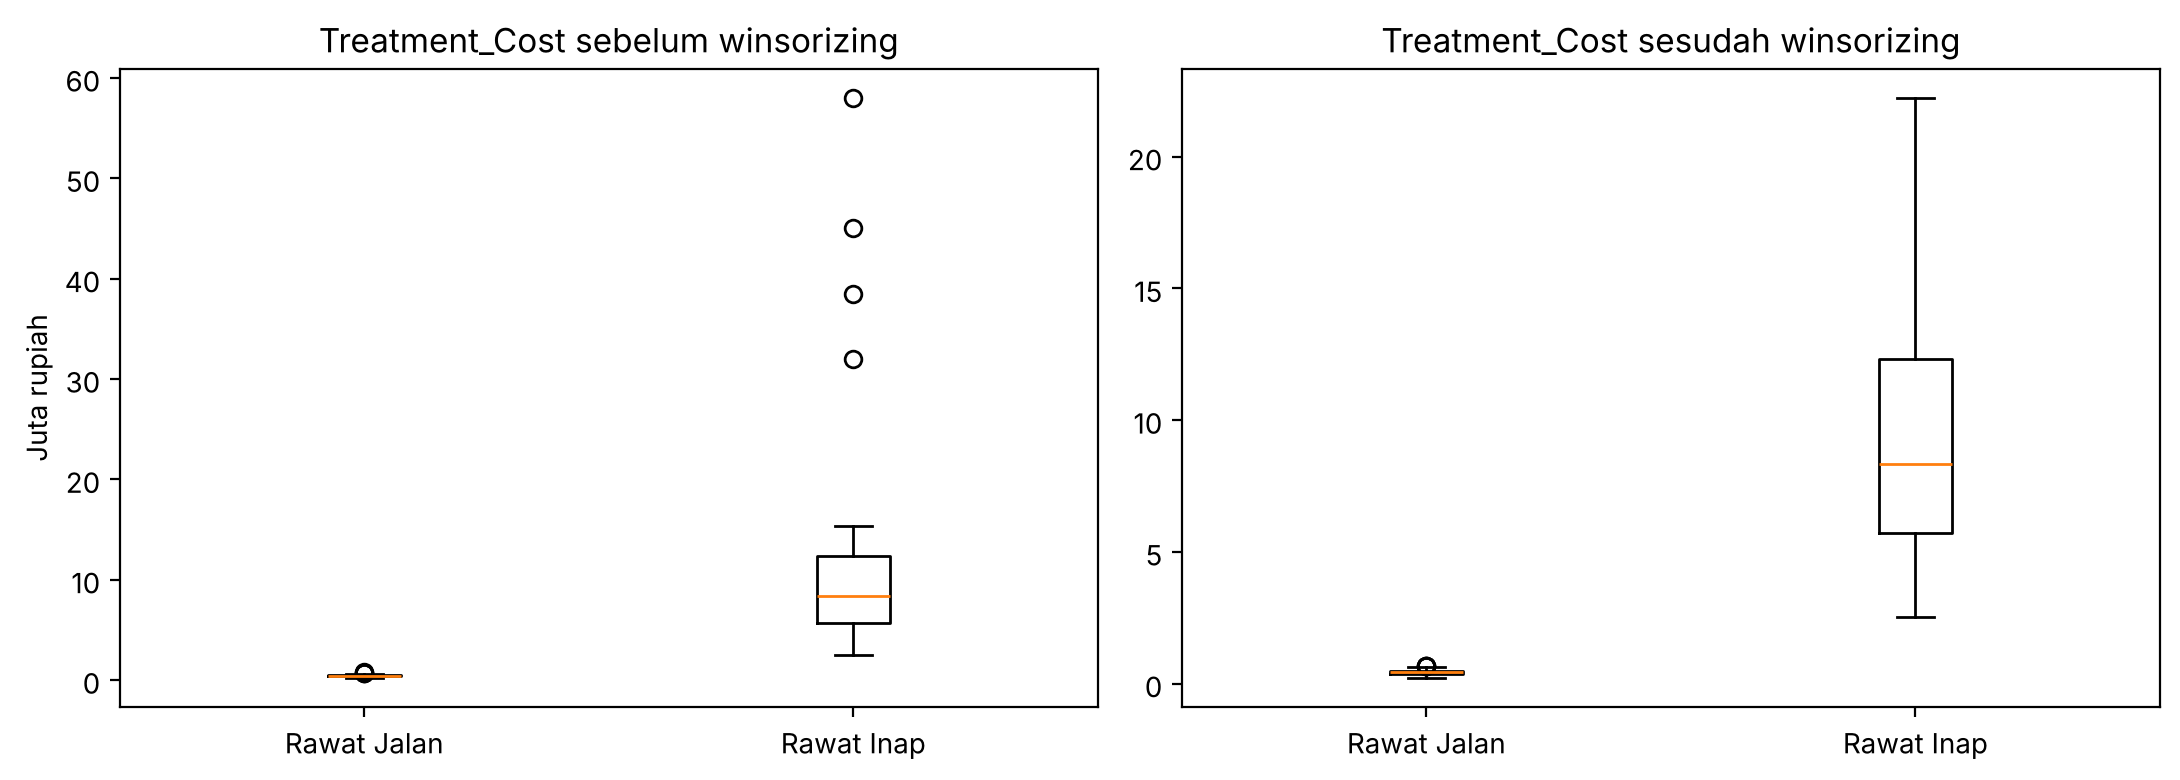

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].boxplot([cost_sebelum[df.Visit_Type == j] / 1e6 for j in ['Rawat Jalan', 'Rawat Inap']], tick_labels=['Rawat Jalan', 'Rawat Inap'])
ax[0].set_title('Treatment_Cost sebelum winsorizing'); ax[0].set_ylabel('Juta rupiah')
ax[1].boxplot([df.loc[df.Visit_Type == j, 'Treatment_Cost'] / 1e6 for j in ['Rawat Jalan', 'Rawat Inap']], tick_labels=['Rawat Jalan', 'Rawat Inap'])
ax[1].set_title('Treatment_Cost sesudah winsorizing')
plt.tight_layout(); plt.savefig('figs/outlier_biaya.png', dpi=150); plt.show()

In [22]:
# Validasi akhir cleansing
assert df.isna().sum().sum() == 0
assert df['Age'].between(0, 110).all() and df['Body_Temperature'].between(34, 42).all()
assert df['Satisfaction_Score'].between(1, 5).all() and (df['Treatment_Cost'] >= 10_000).all()
print('Baris x kolom :', df.shape)
df_bersih = df.copy()
df_bersih.to_csv('hasil/dataset_awal_cleansing.csv', index=False)
df_bersih[kolom_num].describe().T.round(2)

Baris x kolom : (300, 20)


,count,mean,std,min,25%,50%,75%,max
Age,300.0,37.69,21.64,0.0,18.00,36.00,52.00,101.0
Body_Temperature,300.0,36.92,0.62,35.5,36.60,36.80,37.00,39.0
Weight,300.0,55.53,18.30,4.3,47.35,58.05,64.93,147.4
Height,300.0,153.28,20.94,53.8,150.95,158.95,164.40,179.4
Waiting_Time,300.0,27.24,16.02,3.0,15.00,25.00,37.00,69.5
Consultation_Duration,300.0,21.37,14.26,5.0,13.00,17.00,24.00,82.5
Treatment_Cost,300.0,2110511.67,4111446.02,213000.0,382750.00,445000.00,570250.00,22229875.0
Satisfaction_Score,300.0,4.08,0.72,2.0,4.00,4.00,5.00,5.0


In [23]:
perbandingan = pd.concat({'Sebelum': df_awal[kolom_num].describe().T[['mean', 'min', 'max']],
                          'Sesudah': df_bersih[kolom_num].describe().T[['mean', 'min', 'max']]}, axis=1).round(2)
R['banding'] = perbandingan.reset_index().values.tolist()
perbandingan

Sebelum                            Sesudah                      
                             mean       min          max        mean       min         max
Age                         41.98     -10.0        999.0       37.69       0.0       101.0
Body_Temperature            38.83      -5.0        370.0       36.92      35.5        39.0
Weight                     507.96     -20.0      71500.0       55.53       4.3       147.4
Height                     150.37    -150.0        500.0      153.28      53.8       179.4
Waiting_Time                34.16     -60.0       1440.0       27.24       3.0        69.5
Consultation_Duration       26.99     -25.0        900.0       21.37       5.0        82.5
Treatment_Cost         5691797.66 -450000.0  950000000.0  2110511.67  213000.0  22229875.0
Satisfaction_Score           4.43      -1.0         99.0        4.08       2.0         5.0

## 4. Data Transformation

**Input** : `df_bersih` (hasil cleansing).
**Proses** : normalization, discretization, measurement, dan aggregation pada kolom yang relevan.
**Output** : kolom baru hasil transformasi dan tabel agregasi.

### 4.1 Normalization

**Input** : enam kolom numerik hasil cleansing: `Age`, `Weight`, `Height`, `Waiting_Time`, `Consultation_Duration`, `Treatment_Cost`.
**Proses** : dua metode dipakai agar kolom berskala berbeda (usia puluhan, biaya jutaan) dapat dibandingkan:
- **Min-Max** : `(x - min) / (max - min)`, hasil pada rentang 0 sampai 1.
- **Z-score** : `(x - mean) / std`, hasil berpusat di 0 dengan standar deviasi 1.

**Output** : dua belas kolom baru berakhiran `_MinMax` dan `_Z`, beserta tabel pemeriksaan (min dan maks Min-Max, mean dan std Z-score).

In [24]:
dt = df_bersih.copy()
kolom_norm = ['Age', 'Weight', 'Height', 'Waiting_Time', 'Consultation_Duration', 'Treatment_Cost']
for c in kolom_norm:
    dt[c + '_MinMax'] = (dt[c] - dt[c].min()) / (dt[c].max() - dt[c].min())
    dt[c + '_Z'] = (dt[c] - dt[c].mean()) / dt[c].std()

cek = pd.DataFrame({
    'min_minmax': [dt[c + '_MinMax'].min() for c in kolom_norm],
    'max_minmax': [dt[c + '_MinMax'].max() for c in kolom_norm],
    'mean_z': [dt[c + '_Z'].mean() for c in kolom_norm],
    'std_z': [dt[c + '_Z'].std() for c in kolom_norm]}, index=kolom_norm).round(3)
R['normalisasi'] = cek.reset_index().values.tolist()
dt[['Treatment_Cost', 'Treatment_Cost_MinMax', 'Treatment_Cost_Z', 'Age', 'Age_MinMax', 'Age_Z']].head()

,Treatment_Cost,Treatment_Cost_MinMax,Treatment_Cost_Z,Age,Age_MinMax,Age_Z
0,420500.0,0.009425,-0.411050,51,0.504950,0.615320
1,417000.0,0.009266,-0.411902,31,0.306931,-0.309047
2,420500.0,0.009425,-0.411050,32,0.316832,-0.262828
3,421000.0,0.009447,-0.410929,31,0.306931,-0.309047
4,383000.0,0.007721,-0.420171,71,0.702970,1.539686


In [25]:
cek

,min_minmax,max_minmax,mean_z,std_z
Age,0.0,1.0,-0.0,1.0
Weight,0.0,1.0,0.0,1.0
Height,0.0,1.0,0.0,1.0
Waiting_Time,0.0,1.0,0.0,1.0
Consultation_Duration,0.0,1.0,0.0,1.0
Treatment_Cost,0.0,1.0,0.0,1.0


### 4.2 Discretization

**Input** : kolom numerik `Age`, `Systolic`, `Diastolic`, `Waiting_Time`, `Treatment_Cost`, `Weight`, dan `Height`.
**Proses** : data numerik diubah menjadi kategori:
- `Kelompok_Usia` : batas tetap (Anak 0-12, Remaja 13-17, Dewasa 18-59, Lansia 60 ke atas).
- `Kategori_Tekanan_Darah` : berdasarkan sistolik dan diastolik (Normal, Pra-hipertensi, Hipertensi).
- `Kategori_Waktu_Tunggu` : **equal-width** (`pd.cut` dengan 3 interval sama lebar).
- `Kategori_Biaya` : **equal-frequency** (`pd.qcut` dengan 3 kuantil).
- `Kategori_BMI` : khusus pasien dewasa memakai batas BMI Asia-Pasifik (kurus, normal, berat badan lebih, obesitas); pasien non-dewasa diberi label tersendiri karena kategori dewasa tidak berlaku bagi anak.

**Output** : lima kolom kategori baru, jumlah data per kategori, dan grafik sebaran usia serta biaya.

In [26]:
dt['Kelompok_Usia'] = pd.cut(dt['Age'], bins=[-1, 12, 17, 59, 200], labels=['Anak', 'Remaja', 'Dewasa', 'Lansia'])

def kat_td(r):
    if r.Systolic >= 140 or r.Diastolic >= 90: return 'Hipertensi'
    if r.Systolic >= 120 or r.Diastolic >= 80: return 'Pra-hipertensi'
    return 'Normal'
dt['Kategori_Tekanan_Darah'] = dt.apply(kat_td, axis=1)

dt['Kategori_Waktu_Tunggu'] = pd.cut(dt['Waiting_Time'], bins=3, labels=['Singkat', 'Sedang', 'Lama'])
dt['Kategori_Biaya'] = pd.qcut(dt['Treatment_Cost'], q=3, labels=['Rendah', 'Sedang', 'Tinggi'])

dt['BMI'] = (dt['Weight'] / (dt['Height'] / 100) ** 2).round(1)
def kat_bmi(r):
    if r.Age < 18: return 'Non-dewasa'
    if r.BMI < 18.5: return 'Kurus'
    if r.BMI < 23: return 'Normal'
    if r.BMI < 25: return 'Berat badan lebih'
    return 'Obesitas'
dt['Kategori_BMI'] = dt.apply(kat_bmi, axis=1)

R['diskret'] = {c: dt[c].value_counts().to_dict() for c in
                ['Kelompok_Usia', 'Kategori_Tekanan_Darah', 'Kategori_Waktu_Tunggu', 'Kategori_Biaya', 'Kategori_BMI']}
R['batas_tunggu'] = [round(float(x), 1) for x in pd.cut(dt['Waiting_Time'], bins=3, retbins=True)[1]]
R['batas_biaya'] = [round(float(x)) for x in pd.qcut(dt['Treatment_Cost'], q=3, retbins=True)[1]]
for c, v in R['diskret'].items():
    print(c, v)

Kelompok_Usia {'Dewasa': 169, 'Lansia': 66, 'Anak': 40, 'Remaja': 25}
Kategori_Tekanan_Darah {'Pra-hipertensi': 137, 'Normal': 107, 'Hipertensi': 56}
Kategori_Waktu_Tunggu {'Singkat': 152, 'Sedang': 115, 'Lama': 33}
Kategori_Biaya {'Rendah': 101, 'Tinggi': 100, 'Sedang': 99}
Kategori_BMI {'Normal': 85, 'Obesitas': 79, 'Non-dewasa': 65, 'Berat badan lebih': 57, 'Kurus': 14}


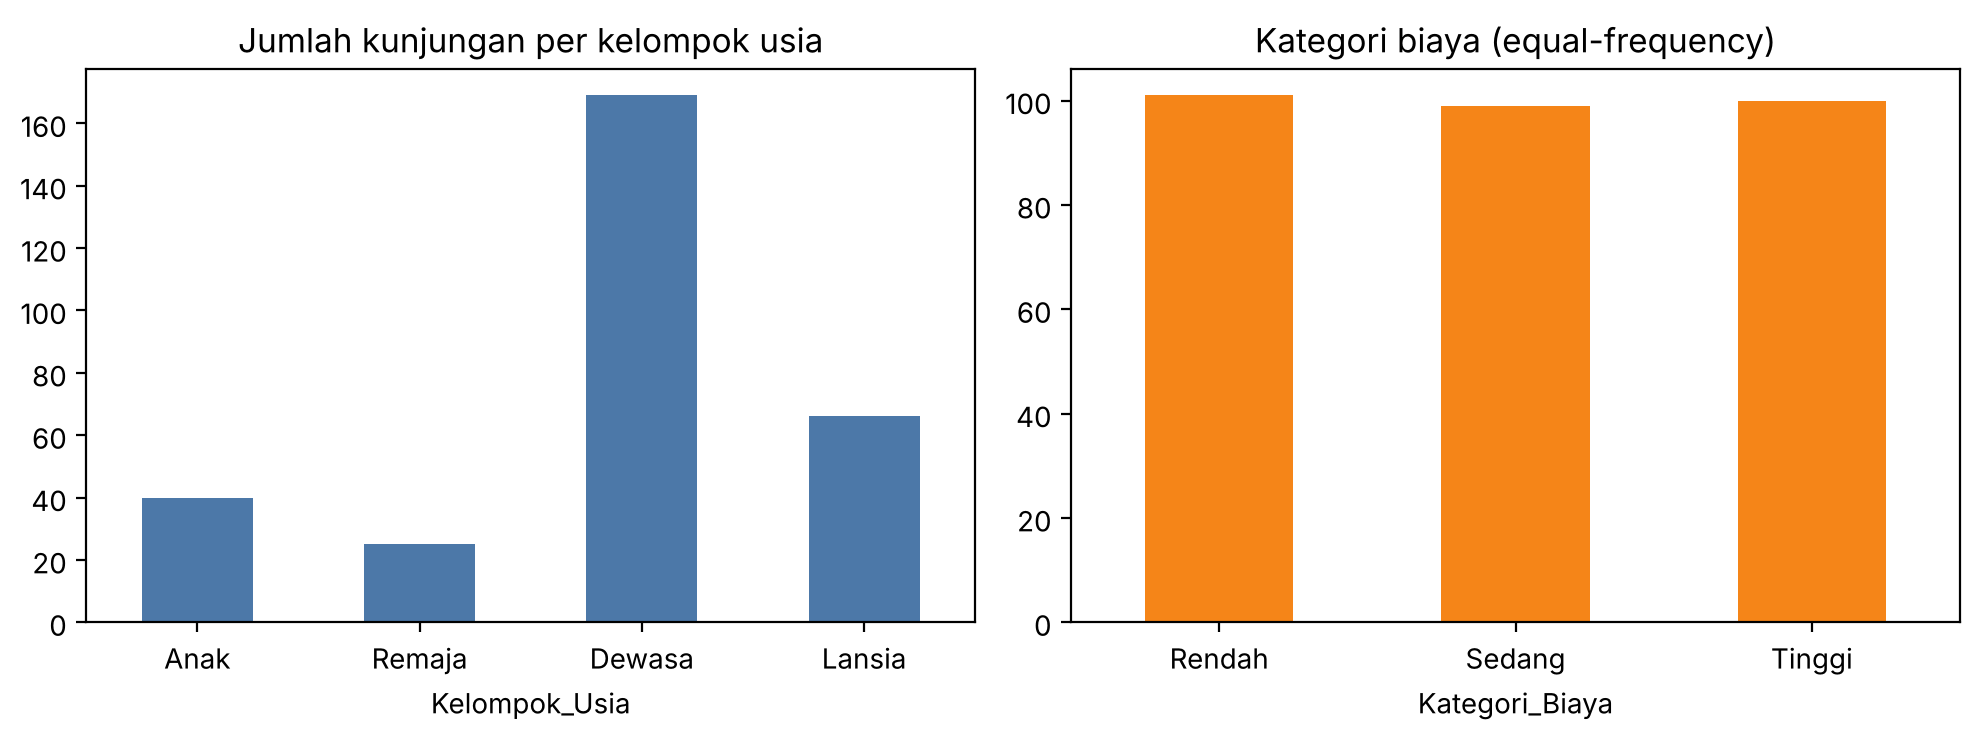

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
dt['Kelompok_Usia'].value_counts().reindex(['Anak', 'Remaja', 'Dewasa', 'Lansia']).plot.bar(ax=ax[0], color='#4C78A8', rot=0)
ax[0].set_title('Jumlah kunjungan per kelompok usia')
dt['Kategori_Biaya'].value_counts().reindex(['Rendah', 'Sedang', 'Tinggi']).plot.bar(ax=ax[1], color='#F58518', rot=0)
ax[1].set_title('Kategori biaya (equal-frequency)')
plt.tight_layout(); plt.savefig('figs/diskretisasi.png', dpi=150); plt.show()

### 4.3 Measurement

**Input** : kolom `Weight`, `Height`, `Treatment_Cost`, dan `Waiting_Time`.
**Proses** : penyesuaian satuan dan penurunan ukuran baru:
- `BMI` (kg per m kuadrat) diturunkan dari berat dan tinggi badan (sudah dibuat pada langkah diskretisasi).
- `Treatment_Cost_Juta` : biaya dalam juta rupiah agar mudah dibaca.
- `Waiting_Time_Jam` : waktu tunggu dalam jam.
- Perbedaan satuan antartabel (menit dan detik pada tabel pelayanan) ditangani pada bagian 5.2.

**Output** : tiga kolom baru: `BMI`, `Treatment_Cost_Juta`, dan `Waiting_Time_Jam`.

In [28]:
dt['Treatment_Cost_Juta'] = (dt['Treatment_Cost'] / 1_000_000).round(3)
dt['Waiting_Time_Jam'] = (dt['Waiting_Time'] / 60).round(2)
dt[['Treatment_Cost', 'Treatment_Cost_Juta', 'Waiting_Time', 'Waiting_Time_Jam', 'Weight', 'Height', 'BMI']].head()

,Treatment_Cost,Treatment_Cost_Juta,Waiting_Time,Waiting_Time_Jam,Weight,Height,BMI
0,420500.0,0.420,15.0,0.25,67.4,154.0,28.4
1,417000.0,0.417,46.0,0.77,69.6,155.7,28.7
2,420500.0,0.420,8.0,0.13,71.1,161.6,27.2
3,421000.0,0.421,10.0,0.17,64.5,166.8,23.2
4,383000.0,0.383,43.0,0.72,57.5,158.1,23.0


### 4.4 Aggregation

**Input** : dataset hasil transformasi pada tingkat kunjungan (300 baris).
**Proses** : data diringkas ke tingkat yang lebih tinggi dengan `groupby` per poliklinik, serta `pivot_table` per bulan dan jenis kunjungan.
**Output** : tabel agregasi per poliklinik (jumlah kunjungan, rata-rata biaya, waktu tunggu, kepuasan) dan tabel per bulan dan jenis kunjungan.

In [29]:
dt['Bulan'] = dt['Visit_Date'].dt.to_period('M').astype(str)

agg_dept = (dt.groupby('Department')
              .agg(Jumlah_Kunjungan=('Visit_ID', 'count'),
                   Rata_Biaya=('Treatment_Cost', 'mean'),
                   Rata_Waktu_Tunggu=('Waiting_Time', 'mean'),
                   Rata_Kepuasan=('Satisfaction_Score', 'mean'))
              .round(1).sort_values('Jumlah_Kunjungan', ascending=False))
R['agg_dept'] = agg_dept.reset_index().values.tolist()
agg_dept

,Jumlah_Kunjungan,Rata_Biaya,Rata_Waktu_Tunggu,Rata_Kepuasan
Department,,,,
Internal Medicine,79,1492582.3,32.2,3.9
Cardiology,48,2839320.3,30.5,4.0
Orthopedics,43,3141508.7,22.9,4.2
ENT,33,600181.8,24.0,4.2
Neurology,30,2834316.7,22.7,4.3
Pediatrics,27,714166.7,30.8,3.9
Dermatology,24,726312.5,21.2,4.2
Obstetrics,16,6394859.4,23.0,4.4


In [30]:
agg_bulan = dt.pivot_table(index='Bulan', columns='Visit_Type', values='Treatment_Cost',
                           aggfunc=['count', 'mean']).round(0)
R['agg_bulan'] = agg_bulan.reset_index().values.tolist()
agg_bulan

count                   mean            
Visit_Type Rawat Inap Rawat Jalan Rawat Inap Rawat Jalan
Bulan                                                   
2026-01            17          91  9599221.0    436995.0
2026-02            18          72  9708021.0    425632.0
2026-03            21          81  9082161.0    420802.0

In [31]:
dt.to_csv('hasil/dataset_awal_transformasi.csv', index=False)
print(dt.shape)
dt.head(3).T

(300, 41)


,0,1,2
Visit_ID,V0001,V0002,V0003
Patient_ID,P0006,P0066,P0140
Patient_Name,Mega Julianto,Indah Sulistyo,Mega Yulianto
Gender,Female,Female,Female
Age,51,31,32
Blood_Type,B,O,A
Department,Orthopedics,Internal Medicine,Cardiology
Diagnosis_Category,Musculoskeletal,Gastrointestinal,Cardiovascular
Visit_Type,Rawat Jalan,Rawat Jalan,Rawat Jalan
Visit_Date,2026-01-01 00:00:00,2026-01-01 00:00:00,2026-01-01 00:00:00


## 5. Data Integration

### 5.1 Joining Table (inner join dan left join)

**Input** : `data_pasien.csv` (identitas pasien) dan `data_kunjungan.csv` (riwayat kunjungan), dihubungkan dengan kunci `Patient_ID`.
**Proses** :
1. Membersihkan kedua tabel dengan aturan yang sama seperti pada bagian cleansing (spasi, penulisan kategori, nama kota).
2. Memeriksa keterhubungan kunci.
3. Menggabungkan dengan `merge` memakai `how='inner'` dan `how='left'`, lalu membandingkan hasilnya.

**Output** : dua tabel gabungan dan perbandingan jumlah barisnya.

In [32]:
def rapikan_teks(d):
    d = d.copy()
    for c in [c for c in d.columns if not pd.api.types.is_numeric_dtype(d[c])]:
        d[c] = d[c].str.strip().str.replace(r'\s+', ' ', regex=True)
    return d

def bersihkan_kunjungan(d):
    d = rapikan_teks(d)
    for c in ['Department', 'Diagnosis_Category', 'Visit_Type']:
        d[c] = standarkan(d[c], PETA[c])
    d['Visit_Date'] = pd.to_datetime(d['Visit_Date'], format='%Y-%m-%d')
    return d

pasien_b = rapikan_teks(pasien)
pasien_b['Patient_Name'] = pasien_b['Patient_Name'].str.title()
pasien_b['Gender'] = standarkan(pasien_b['Gender'], PETA['Gender'])
pasien_b['Blood_Type'] = standarkan(pasien_b['Blood_Type'], PETA['Blood_Type'])
pasien_b['Address'] = pasien_b['Address'].str.replace(r',\s*(\w+)$', lambda m: ', ' + m.group(1).title(), regex=True)
pasien_b.loc[~pasien_b['Age'].between(0, 110), 'Age'] = np.nan

kunjungan_b = bersihkan_kunjungan(kunjungan)

print('Patient_ID duplikat pada tabel pasien :', int(pasien_b['Patient_ID'].duplicated().sum()))
print('Kunjungan dengan Patient_ID tidak ada di tabel pasien :', int((~kunjungan_b['Patient_ID'].isin(pasien_b['Patient_ID'])).sum()))
print('Pasien yang tidak pernah berkunjung :', int((~pasien_b['Patient_ID'].isin(kunjungan_b['Patient_ID'])).sum()))

Patient_ID duplikat pada tabel pasien : 0
Kunjungan dengan Patient_ID tidak ada di tabel pasien : 26
Pasien yang tidak pernah berkunjung : 107


In [33]:
gabung_inner = kunjungan_b.merge(pasien_b, on='Patient_ID', how='inner')
gabung_left  = kunjungan_b.merge(pasien_b, on='Patient_ID', how='left', indicator=True)

R['join'] = {
    'pasien': len(pasien_b), 'kunjungan': len(kunjungan_b),
    'inner': len(gabung_inner), 'left': len(gabung_left),
    'left_tanpa_pasien': int((gabung_left['_merge'] == 'left_only').sum()),
    'kunjungan_tak_cocok_unik': int(kunjungan_b.loc[~kunjungan_b['Patient_ID'].isin(pasien_b['Patient_ID']), 'Patient_ID'].nunique()),
    'pasien_tanpa_kunjungan': int((~pasien_b['Patient_ID'].isin(kunjungan_b['Patient_ID'])).sum())}
pd.DataFrame({'Jenis join': ['Tabel pasien', 'Tabel kunjungan', 'Inner join', 'Left join'],
              'Jumlah baris': [len(pasien_b), len(kunjungan_b), len(gabung_inner), len(gabung_left)]})

,Jenis join,Jumlah baris
0,Tabel pasien,280
1,Tabel kunjungan,320
2,Inner join,294
3,Left join,320


In [34]:
gabung_left[gabung_left['_merge'] == 'left_only'].head(5)

,Visit_ID,Patient_ID,Department,Diagnosis_Category,Visit_Type,Visit_Date,Waiting_Time,Treatment_Cost,Patient_Name,Gender,Age,Blood_Type,Address,_merge
0,VK0001,P0295,NaN,Infectious Disease,Rawat Jalan,2026-01-01,9.0,455000.0,NaN,NaN,NaN,NaN,NaN,left_only
4,VK0005,P0281,Internal Medicine,Infectious Disease,Rawat Jalan,2026-01-02,58.0,554000.0,NaN,NaN,NaN,NaN,NaN,left_only
8,VK0009,P0299,Orthopedics,Injury/Trauma,Rawat Jalan,2026-01-02,22.0,514000.0,NaN,NaN,NaN,NaN,NaN,left_only
9,VK0010,P0297,Orthopedics,Musculoskeletal,Rawat Jalan,2026-01-02,15.0,370000.0,NaN,NaN,NaN,NaN,NaN,left_only
27,VK0028,P0289,Internal Medicine,Gastrointestinal,Rawat Jalan,2026-01-07,68.0,449000.0,NaN,NaN,NaN,NaN,NaN,left_only


In [35]:
gabung_inner.to_csv('hasil/join_inner_pasien_kunjungan.csv', index=False)
gabung_left.drop(columns='_merge').to_csv('hasil/join_left_kunjungan_pasien.csv', index=False)
gabung_inner.head()

,Visit_ID,Patient_ID,Department,Diagnosis_Category,Visit_Type,Visit_Date,Waiting_Time,Treatment_Cost,Patient_Name,Gender,Age,Blood_Type,Address
0,VK0002,P0145,Dermatology,Skin Disorder,Rawat Jalan,2026-01-01,59.0,377000.0,Hendra Hartono,Male,32.0,O,"Jl. Veteran No. 38, Mojokerto"
1,VK0003,P0088,Internal Medicine,Gastrointestinal,Rawat Jalan,2026-01-01,94.0,513000.0,Ilham Ramadhan,Male,27.0,B,"Jl. Kemuning No. 3, Surabaya"
2,VK0004,P0053,Internal Medicine,Metabolic/Endocrine,Rawat Jalan,2026-01-02,20.0,405000.0,Joko Setiawan,Male,NaN,A,"Jl. Cendana No. 30, Sidoarjo"
3,VK0006,P0106,ENT,Respiratory,Rawat Jalan,2026-01-02,39.0,250000.0,Rudi Maulana,Male,14.0,B,"Jl. Sudirman No. 83, Gresik"
4,VK0007,P0073,ENT,Respiratory,Rawat Inap,2026-01-02,5.0,6847000.0,Fikri Setiawan,Male,34.0,A,"Jl. Mawar No. 13, Surabaya"


Inner join hanya mempertahankan kunjungan yang Patient_ID-nya ada pada tabel pasien, sehingga baris kunjungan dari pasien yang belum terdaftar ikut terbuang. Left join (tabel kunjungan di sisi kiri) mempertahankan seluruh kunjungan dan mengisi kolom identitas dengan `NaN` bila pasien tidak ditemukan. Untuk analisis riwayat kunjungan, left join lebih aman karena tidak menghilangkan data transaksi.

### 5.2 Appending Table (pd.concat)

Appending dilakukan pada tabel yang strukturnya sama tetapi barisnya berbeda. Terdapat tiga pasangan tabel.

#### a. Kunjungan Januari dan Februari

**Input** : `kunjungan_januari.csv` dan `kunjungan_februari.csv` (struktur kolom identik).
**Proses** : kedua tabel dibersihkan, diperiksa kesamaan kolom, lalu digabung dengan `pd.concat(ignore_index=True)`.
**Output** : tabel kunjungan Januari-Februari.

In [36]:
jan_b, feb_b = bersihkan_kunjungan(k_jan), bersihkan_kunjungan(k_feb)
assert list(jan_b.columns) == list(feb_b.columns)

kunj_jan_feb = pd.concat([jan_b, feb_b], ignore_index=True)
kunj_jan_feb['Bulan'] = kunj_jan_feb['Visit_Date'].dt.to_period('M').astype(str)

R['append_kunjungan'] = {'januari': len(jan_b), 'februari': len(feb_b), 'gabungan': len(kunj_jan_feb),
                         'visit_id_duplikat': int(kunj_jan_feb['Visit_ID'].duplicated().sum()),
                         'rentang': [str(kunj_jan_feb['Visit_Date'].min().date()), str(kunj_jan_feb['Visit_Date'].max().date())]}
print(R['append_kunjungan'])
kunj_jan_feb.groupby('Bulan').size()

{'januari': 70, 'februari': 62, 'gabungan': 132, 'visit_id_duplikat': 0, 'rentang': ['2026-01-01', '2026-02-27']}


Bulan
2026-01    70
2026-02    62
dtype: int64

In [37]:
kunj_jan_feb.to_csv('hasil/append_kunjungan_jan_feb.csv', index=False)
kunj_jan_feb.sample(5, random_state=1)

,Visit_ID,Patient_ID,Department,Diagnosis_Category,Visit_Type,Visit_Date,Waiting_Time,Treatment_Cost,Bulan
75,VF006,P0257,ENT,Respiratory,Rawat Jalan,2026-02-03,29.0,402000.0,2026-02
35,VJ036,P0161,ENT,Respiratory,Rawat Jalan,2026-01-16,51.0,414000.0,2026-01
51,VJ052,P0059,Internal Medicine,Metabolic/Endocrine,Rawat Jalan,2026-01-24,81.0,460000.0,2026-01
5,VJ006,P0121,Neurology,Neurological,Rawat Jalan,2026-01-01,30.0,448000.0,2026-01
36,VJ037,P0029,Cardiology,Cardiovascular,Rawat Jalan,2026-01-16,14.0,543000.0,2026-01


#### b. Pelayanan (menit dan detik)

**Input** : `pelayanan_menit.csv` (durasi dalam menit) dan `pelayanan_detik.csv` (durasi dalam detik).
**Proses** : durasi pada tabel detik dibagi 60 agar satuannya sama (menit), baru kedua tabel digabung. Jika satuan tidak disamakan, rata-rata durasi akan keliru karena nilai detik 60 kali lebih besar.
**Output** : tabel pelayanan dengan satuan seragam.

In [38]:
rata_salah = pd.concat([pel_menit['Service_Duration'], pel_detik['Service_Duration']]).mean()

pm, pdt = rapikan_teks(pel_menit), rapikan_teks(pel_detik)
pdt['Service_Duration'] = (pdt['Service_Duration'] / 60).round(2)
pm['Satuan_Asli'], pdt['Satuan_Asli'] = 'menit', 'detik'
for d in (pm, pdt):
    d['Department'] = standarkan(d['Department'], PETA['Department'])
    d['Service_Date'] = pd.to_datetime(d['Service_Date'], format='%Y-%m-%d')

assert list(pm.columns) == list(pdt.columns)
pelayanan = pd.concat([pm, pdt], ignore_index=True)

R['append_pelayanan'] = {'menit': len(pm), 'detik': len(pdt), 'gabungan': len(pelayanan),
    'rata_durasi_salah': round(float(rata_salah), 2),
    'rata_durasi_benar': round(float(pelayanan['Service_Duration'].mean()), 2),
    'service_id_duplikat': int(pelayanan['Service_ID'].duplicated().sum()),
    'missing_durasi': int(pelayanan['Service_Duration'].isna().sum()),
    'missing_biaya': int(pelayanan['Service_Cost'].isna().sum())}
print(R['append_pelayanan'])
pelayanan.groupby('Source_System')['Service_Duration'].describe().round(2)

{'menit': 190, 'detik': 190, 'gabungan': 380, 'rata_durasi_salah': 827.4, 'rata_durasi_benar': 24.35, 'service_id_duplikat': 0, 'missing_durasi': 8, 'missing_biaya': 8}


,count,mean,std,min,25%,50%,75%,max
Source_System,,,,,,,,
SIM-Penunjang,186.0,27.22,13.62,7.65,17.95,24.32,32.45,79.85
SIMRS-Poliklinik,186.0,21.47,16.47,3.00,11.00,15.00,26.00,71.00


In [39]:
pelayanan.groupby('Service_Type').agg(Jumlah=('Service_ID', 'count'),
                                       Rata_Durasi_Menit=('Service_Duration', 'mean'),
                                       Rata_Biaya=('Service_Cost', 'mean')).round(1)

,Jumlah,Rata_Durasi_Menit,Rata_Biaya
Service_Type,,,
Farmasi,52,10.0,149235.3
Konsultasi Dokter,105,14.8,190543.7
Laboratorium,81,25.3,293846.2
Radiologi,62,22.1,439754.1
Tindakan Medis,80,46.8,986291.1


In [40]:
pelayanan.to_csv('hasil/append_pelayanan.csv', index=False)

#### c. Kunjungan harian dan mingguan (perbedaan tingkat agregasi)

**Input** : `kunjungan_harian.csv` (per hari, 1 Jan - 28 Feb 2026) dan `kunjungan_mingguan.csv` (per minggu, mulai 2 Mar 2026).
**Proses** : tingkat agregasi berbeda (hari dan minggu), sehingga data harian diagregasi dulu menjadi mingguan:
- `Jumlah_Kunjungan` dan `Total_Biaya` dijumlahkan.
- `Rata_Rata_Waktu_Tunggu` dihitung sebagai **rata-rata tertimbang** jumlah kunjungan, dan hari tanpa kunjungan (nilai tunggu kosong) diabaikan karena kosongnya memang wajar.
- Minggu mengikuti penomoran ISO dan dimulai hari Senin, sama seperti tabel mingguan.

Setelah itu dilakukan `pd.concat`.
**Output** : deret waktu mingguan Januari sampai Mei 2026.

In [41]:
h = harian.copy()
h['Tanggal'] = pd.to_datetime(h['Tanggal'], format='%Y-%m-%d')
R['harian_missing_tunggu'] = int(h['Rata_Rata_Waktu_Tunggu'].isna().sum())
R['harian_missing_dengan_kunjungan'] = int((h['Rata_Rata_Waktu_Tunggu'].isna() & (h['Jumlah_Kunjungan'] > 0)).sum())
print('Missing waktu tunggu pada data harian :', R['harian_missing_tunggu'])
print('Dari jumlah itu yang sebenarnya ada kunjungan :', R['harian_missing_dengan_kunjungan'])

h['Tanggal_Awal_Minggu'] = h['Tanggal'] - pd.to_timedelta(h['Tanggal'].dt.dayofweek, unit='D')
h['Minggu_Ke'] = h['Tanggal'].dt.isocalendar().week.astype(int)
h['tunggu_x_jumlah'] = h['Rata_Rata_Waktu_Tunggu'] * h['Jumlah_Kunjungan']
h['jumlah_valid'] = h['Jumlah_Kunjungan'].where(h['Rata_Rata_Waktu_Tunggu'].notna(), 0)

harian_mingguan = (h.groupby(['Minggu_Ke', 'Tanggal_Awal_Minggu', 'Department'], as_index=False)
                     .agg(Jumlah_Kunjungan=('Jumlah_Kunjungan', 'sum'), Total_Biaya=('Total_Biaya', 'sum'),
                          tunggu_x_jumlah=('tunggu_x_jumlah', 'sum'), jumlah_valid=('jumlah_valid', 'sum'),
                          Jumlah_Hari=('Tanggal', 'nunique')))
harian_mingguan['Rata_Rata_Waktu_Tunggu'] = (harian_mingguan['tunggu_x_jumlah'] / harian_mingguan['jumlah_valid']).round(1)
harian_mingguan = harian_mingguan.drop(columns=['tunggu_x_jumlah', 'jumlah_valid'])

m = mingguan.copy()
m['Tanggal_Awal_Minggu'] = pd.to_datetime(m['Tanggal_Awal_Minggu'], format='%Y-%m-%d')
m['Jumlah_Hari'] = 7

kolom_urut = ['Minggu_Ke', 'Tanggal_Awal_Minggu', 'Department', 'Jumlah_Kunjungan', 'Total_Biaya', 'Rata_Rata_Waktu_Tunggu', 'Jumlah_Hari']
deret_mingguan = pd.concat([harian_mingguan[kolom_urut], m[kolom_urut]], ignore_index=True).sort_values(['Tanggal_Awal_Minggu', 'Department']).reset_index(drop=True)

R['append_mingguan'] = {'harian_asli': len(h), 'harian_jadi_mingguan': len(harian_mingguan), 'mingguan_asli': len(m),
                        'gabungan': len(deret_mingguan), 'jumlah_minggu': int(deret_mingguan['Tanggal_Awal_Minggu'].nunique()),
                        'missing_tunggu_akhir': int(deret_mingguan['Rata_Rata_Waktu_Tunggu'].isna().sum()),
                        'minggu_parsial': sorted(deret_mingguan.loc[deret_mingguan['Jumlah_Hari'] < 7, 'Minggu_Ke'].unique().tolist())}
print(R['append_mingguan'])
deret_mingguan.head(10)

Missing waktu tunggu pada data harian : 97
Dari jumlah itu yang sebenarnya ada kunjungan : 0
{'harian_asli': 472, 'harian_jadi_mingguan': 72, 'mingguan_asli': 96, 'gabungan': 168, 'jumlah_minggu': 21, 'missing_tunggu_akhir': 0, 'minggu_parsial': [1, 9]}


,Minggu_Ke,Tanggal_Awal_Minggu,Department,Jumlah_Kunjungan,Total_Biaya,Rata_Rata_Waktu_Tunggu,Jumlah_Hari
0,1,2025-12-29,Cardiology,3,1989000,56.7,4
1,1,2025-12-29,Dermatology,7,1772000,13.7,4
2,1,2025-12-29,ENT,5,1749000,21.9,4
3,1,2025-12-29,Internal Medicine,6,4455000,23.3,4
4,1,2025-12-29,Neurology,5,7340000,31.8,4
5,1,2025-12-29,Obstetrics,12,19657000,27.6,4
6,1,2025-12-29,Orthopedics,5,5993000,35.9,4
7,1,2025-12-29,Pediatrics,6,3508000,34.6,4
8,2,2026-01-05,Cardiology,14,19768000,38.9,7
9,2,2026-01-05,Dermatology,10,2487000,26.4,7


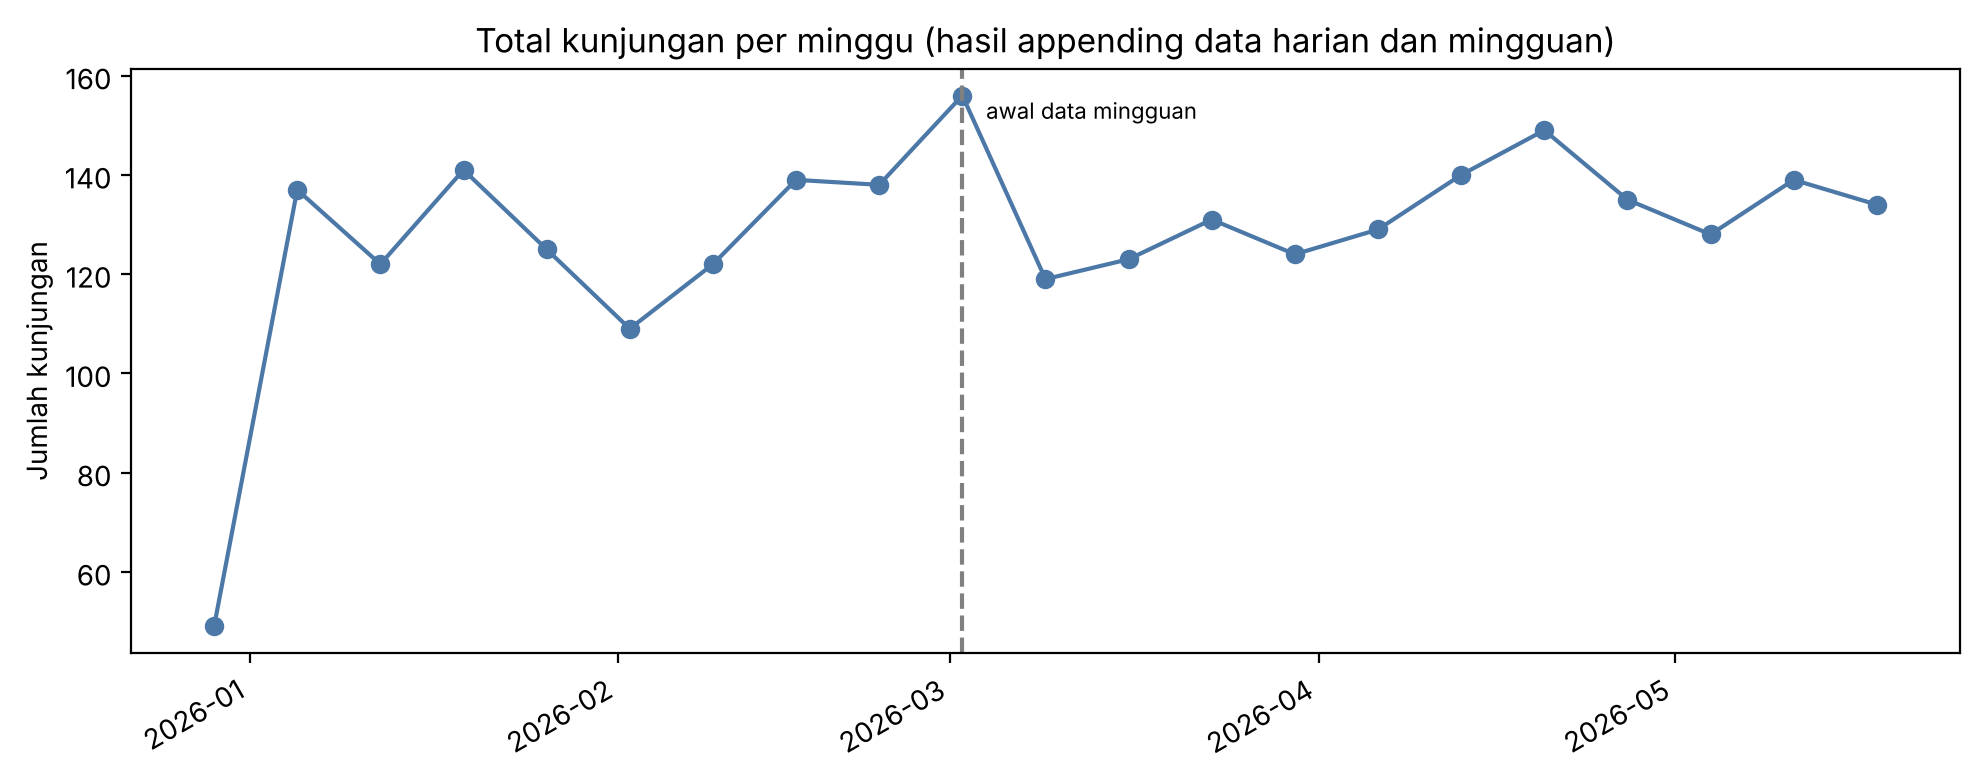

In [42]:
total_mingguan = deret_mingguan.groupby('Tanggal_Awal_Minggu')['Jumlah_Kunjungan'].sum()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(total_mingguan.index, total_mingguan.values, marker='o', color='#4C78A8')
ax.axvline(pd.Timestamp('2026-03-02'), color='gray', ls='--')
ax.text(pd.Timestamp('2026-03-04'), total_mingguan.max() * 0.97, 'awal data mingguan', fontsize=8)
ax.set_title('Total kunjungan per minggu (hasil appending data harian dan mingguan)')
ax.set_ylabel('Jumlah kunjungan'); fig.autofmt_xdate()
plt.tight_layout(); plt.savefig('figs/deret_mingguan.png', dpi=150); plt.show()

In [43]:
deret_mingguan.to_csv('hasil/append_kunjungan_mingguan.csv', index=False)

## 6. Ringkasan Hasil

In [44]:
R['akhir'] = {'dataset_cleansing': list(df_bersih.shape), 'dataset_transformasi': list(dt.shape)}
with open('hasil/ringkasan.json', 'w', encoding='utf-8') as f:
    json.dump(R, f, ensure_ascii=False, indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))

print('Dataset akhir cleansing   :', df_bersih.shape)
print('Dataset akhir transformasi:', dt.shape)
print('Missing value awal -> akhir :', R['missing_total_sebelum'], '->', R['missing_total_sesudah'])
print('File hasil:', sorted(os.listdir('hasil')))

Dataset akhir cleansing   : (300, 20)
Dataset akhir transformasi: (300, 41)
Missing value awal -> akhir : 206 -> 0
File hasil: ['append_kunjungan_jan_feb.csv', 'append_kunjungan_mingguan.csv', 'append_pelayanan.csv', 'dataset_awal_cleansing.csv', 'dataset_awal_transformasi.csv', 'join_inner_pasien_kunjungan.csv', 'join_left_kunjungan_pasien.csv', 'ringkasan.json']
